# Day 4 — Baseline Machine-Learning Models

**Project:** Tehran House Price Prediction

## Goal
Train and compare simple baseline regression models using the cleaned dataset. All preprocessing is fitted on the training set through a scikit-learn pipeline.

**Target:** `Price`  
**Inputs:** `Area`, `Room`, `Parking`, `Warehouse`, `Elevator`, `Address`

`Price(USD)` and `Price_per_sqm` are deliberately excluded because they are derived from the target and would cause target leakage.

## 1. Imports and project paths
Run the notebook from the project root or from the `notebooks` folder.

In [12]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.preprocessing import FunctionTransformer
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore", category=FutureWarning)

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / "data" / "processed" / "tehran_house_prices_cleaned.csv"
FIGURES_DIR = PROJECT_ROOT / "figures"
REPORTS_DIR = PROJECT_ROOT / "reports"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA_PATH)

print("Dataset:", df.shape)
display(df.head())

Dataset: (3256, 8)


,Area,Room,Parking,Warehouse,Elevator,Address,Price,Price(USD)
0,63,1,True,True,True,Shahran,1.850000e+09,61666.67
1,60,1,True,True,True,Shahran,1.850000e+09,61666.67
2,79,2,True,True,True,Pardis,5.500000e+08,18333.33
3,95,2,True,True,True,Shahrake Qods,9.025000e+08,30083.33
4,123,2,True,True,True,Shahrake Gharb,7.000000e+09,233333.33


## 2. Validate the dataset and select features

The notebook uses the cleaned Day 2 dataset. The target is the total price in rials.

In [13]:
TARGET = "Price"
NUMERIC_FEATURES = ["Area", "Room"]
BOOLEAN_FEATURES = ["Parking", "Warehouse", "Elevator"]
CATEGORICAL_FEATURES = ["Address"]
FEATURES = NUMERIC_FEATURES + BOOLEAN_FEATURES + CATEGORICAL_FEATURES

required_columns = FEATURES + [TARGET]
missing_columns = [c for c in required_columns if c not in df.columns]
if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

model_df = df[required_columns].copy()


for col in NUMERIC_FEATURES + [TARGET]:
    model_df[col] = pd.to_numeric(model_df[col], errors="coerce")

for col in BOOLEAN_FEATURES:
    if model_df[col].dtype == "object":
        mapping = {"True": True, "False": False, "true": True, "false": False,
                   "1": True, "0": False, 1: True, 0: False}
        model_df[col] = model_df[col].map(mapping)

model_df = model_df.dropna(subset=[TARGET])
model_df = model_df.loc[model_df[TARGET] > 0].copy()
model_df["Address"] = model_df["Address"].fillna("Unknown").astype(str)

X = model_df[FEATURES].copy()
y = model_df[TARGET].copy()

assert "Price(USD)" not in X.columns
assert "Price_per_sqm" not in X.columns
assert TARGET not in X.columns

print("Rows used:", len(model_df))
print("X shape:", X.shape)
print("y shape:", y.shape)
print("Missing target values:", y.isna().sum())
display(X.dtypes)

Rows used: 3256
X shape: (3256, 6)
y shape: (3256,)
Missing target values: 0


Area         int64
Room         int64
Parking       bool
Warehouse     bool
Elevator      bool
Address        str
dtype: object

## 3. Create a train/test split

The test set is held out for evaluation. The encoder and imputers are fitted only on training data via the pipelines.

In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))

Training rows: 2604
Test rows: 652


## 4. Build leakage-safe preprocessing

Numeric values are median-imputed; Boolean features are most-frequent-imputed; neighborhoods are one-hot encoded. Unknown neighborhoods in the test set are safely ignored.

In [19]:
numeric_features = ["Area", "Room"]
boolean_features = ["Parking", "Warehouse", "Elevator"]
categorical_features = ["Address"]

numeric_transformer = SimpleImputer(strategy="median")
boolean_transformer = Pipeline(steps=[
    ("to_numeric", FunctionTransformer(
        lambda x: x.astype("float64"), feature_names_out="one-to-one"
    )),
    ("imputer", SimpleImputer(strategy="most_frequent"))
])
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("bool", boolean_transformer, boolean_features),
    ("cat", categorical_transformer, categorical_features)
])

## 5. Train baseline models

The dummy regressor provides a simple reference point. Other models are compared against it on the same held-out test set.

In [20]:
models = {
    "Dummy median baseline": DummyRegressor(strategy="median"),
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(
        random_state=42,
        min_samples_leaf=5
    ),
    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        min_samples_leaf=2,
        n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        random_state=42,
        n_estimators=100,
        learning_rate=0.05,
        max_depth=2
    ),
}

results = []
fitted_models = {}
predictions = {}

for name, estimator in models.items():
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", estimator)
    ])
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)

    fitted_models[name] = pipeline
    predictions[name] = y_pred
    results.append({
        "Model": name,
        "MAE_rials": mean_absolute_error(y_test, y_pred),
        "RMSE_rials": mean_squared_error(y_test, y_pred) ** 0.5,
        "R2": r2_score(y_test, y_pred),
    })

results_df = pd.DataFrame(results).sort_values("RMSE_rials").reset_index(drop=True)
display(results_df)

,Model,MAE_rials,RMSE_rials,R2
0,Gradient Boosting,2.250352e+09,4.975560e+09,0.589141
1,Random Forest,1.912439e+09,5.105464e+09,0.567407
2,Decision Tree,2.113373e+09,5.298891e+09,0.534007
3,Linear Regression,2.268592e+09,6.018679e+09,0.398811
4,Dummy median baseline,3.924260e+09,8.157601e+09,-0.104419


## 6. Compare model performance

- **MAE:** average absolute prediction error in rials; lower is better.
- **RMSE:** penalizes larger errors more strongly; lower is better.
- **R²:** relative fit compared with predicting the test-set mean; higher is generally better.

Do not assume one model is best before examining the actual results.

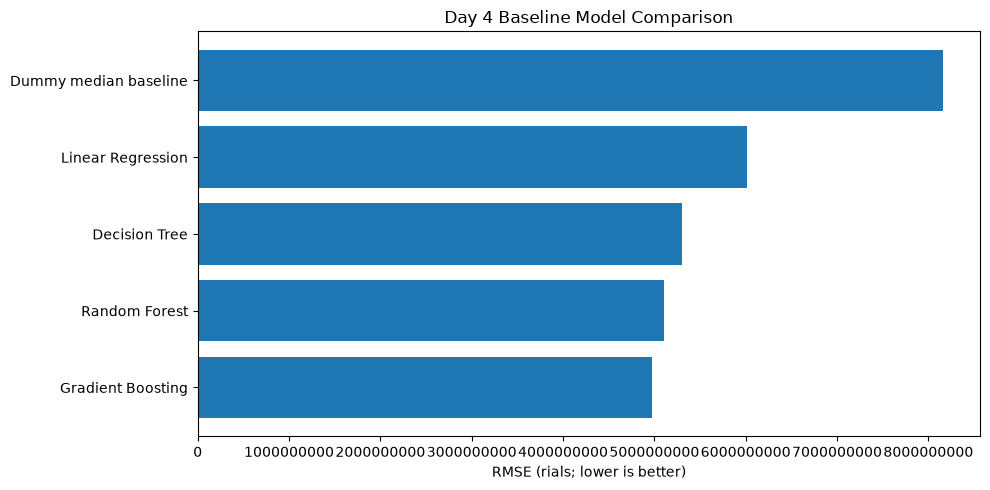

Saved results: D:\python\tehran-house-price-prediction\reports\day4_baseline_results.csv
Saved figure: D:\python\tehran-house-price-prediction\figures\day4_baseline_model_comparison.png


In [21]:
results_path = REPORTS_DIR / "day4_baseline_results.csv"
results_df.to_csv(results_path, index=False)

plot_df = results_df.sort_values("RMSE_rials", ascending=True)
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(plot_df["Model"], plot_df["RMSE_rials"])
ax.set_xlabel("RMSE (rials; lower is better)")
ax.set_title("Day 4 Baseline Model Comparison")
ax.ticklabel_format(style="plain", axis="x")
fig.tight_layout()

plot_path = FIGURES_DIR / "day4_baseline_model_comparison.png"
fig.savefig(plot_path, dpi=150, bbox_inches="tight")
plt.show()

print("Saved results:", results_path)
print("Saved figure:", plot_path)

## 7. Inspect the best model's predictions

This is a quick diagnostic only. The test set should not be used repeatedly to tune model choices; formal cross-validation and tuning are planned for Day 5.

Lowest test RMSE model: Gradient Boosting


,Actual_Price_rials,Predicted_Price_rials
0,8.350000e+08,2.046939e+09
1,3.000000e+09,2.540672e+09
2,8.680000e+08,1.944285e+09
3,5.950000e+09,4.974616e+09
4,1.800000e+09,2.540672e+09
5,1.900000e+09,2.540672e+09
6,4.200000e+09,3.479069e+09
7,1.330000e+10,1.540977e+10
8,1.840000e+09,1.675106e+09
9,6.200000e+09,5.695892e+09


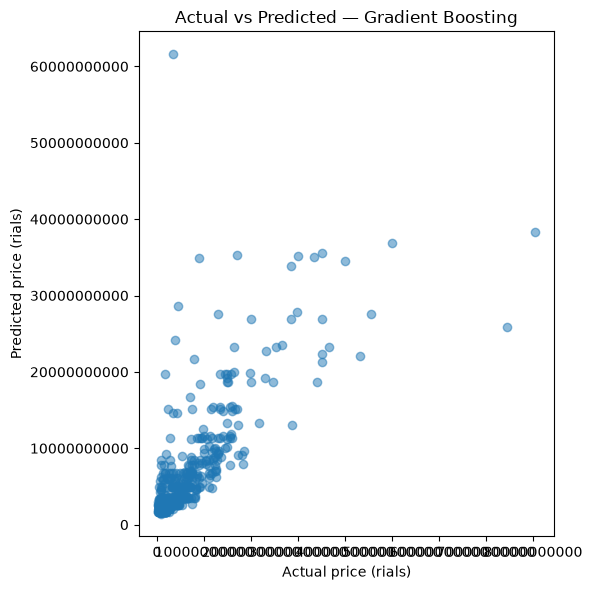

Saved figure: D:\python\tehran-house-price-prediction\figures\day4_actual_vs_predicted.png


In [22]:
best_model_name = results_df.iloc[0]["Model"]
best_pipeline = fitted_models[best_model_name]
best_pred = predictions[best_model_name]

print("Lowest test RMSE model:", best_model_name)

comparison = pd.DataFrame({
    "Actual_Price_rials": y_test.to_numpy(),
    "Predicted_Price_rials": best_pred,
})
display(comparison.head(15))

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(comparison["Actual_Price_rials"], comparison["Predicted_Price_rials"], alpha=0.5)
ax.set_xlabel("Actual price (rials)")
ax.set_ylabel("Predicted price (rials)")
ax.set_title(f"Actual vs Predicted — {best_model_name}")
ax.ticklabel_format(style="plain", axis="both")
fig.tight_layout()

pred_plot_path = FIGURES_DIR / "day4_actual_vs_predicted.png"
fig.savefig(pred_plot_path, dpi=150, bbox_inches="tight")
plt.show()

print("Saved figure:", pred_plot_path)

## 8. Day 4 conclusions template

Fill this in after inspecting `results_df`. Do not invent or estimate scores.

- Best baseline by test RMSE: **[write model name]**
- MAE of that model: **[copy exact value from results_df]** rials
- RMSE of that model: **[copy exact value from results_df]** rials
- R² of that model: **[copy exact value from results_df]**
- Main limitation: a single train/test split may produce a split-specific result; Day 5 will use cross-validation and tuning.

## 9. Leakage and reproducibility checks

In [23]:
assert set(FEATURES).issubset(X.columns)
assert "Price" not in X.columns
assert "Price(USD)" not in X.columns
assert "Price_per_sqm" not in X.columns
assert len(X_train) + len(X_test) == len(X)
assert results_df[["MAE_rials", "RMSE_rials", "R2"]].notna().all().all()

print("Day 4 checks passed.")
print("Results file:", results_path)
print("Figures:", plot_path, pred_plot_path)

Day 4 checks passed.
Results file: D:\python\tehran-house-price-prediction\reports\day4_baseline_results.csv
Figures: D:\python\tehran-house-price-prediction\figures\day4_baseline_model_comparison.png D:\python\tehran-house-price-prediction\figures\day4_actual_vs_predicted.png
